In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# Check your exact filename and update if different
import os
print("Files in current folder:")
for f in os.listdir():
    if f.endswith('.csv'):
        print(f" {f}")

Files in current folder:
 DataCoSupplyChainDataset.csv
 DescriptionDataCoSupplyChain.csv
 tokenized_access_logs.csv


In [6]:
import os
print("Files in current folder:")
for f in os.listdir():
    if f.endswith('.csv'):
        print(f" {f}")

Files in current folder:
 DataCoSupplyChainDataset.csv
 DescriptionDataCoSupplyChain.csv
 tokenized_access_logs.csv
 yellow_tripdata_2015-01.csv
 yellow_tripdata_2016-01.csv
 yellow_tripdata_2016-02.csv
 yellow_tripdata_2016-03.csv


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# Load all four taxi files and combine them
files = [
    'yellow_tripdata_2015-01.csv',
    'yellow_tripdata_2016-01.csv',
    'yellow_tripdata_2016-02.csv',
    'yellow_tripdata_2016-03.csv'
]

dfs = []
for file in files:
    print(f"Loading {file}...")
    temp = pd.read_csv(file, nrows=500000)
    temp['source_file'] = file
    dfs.append(temp)

df = pd.concat(dfs, ignore_index=True)

print(f"\nCOMBINED DATASET LOADED")
print("=" * 50)
print(f"Total records: {len(df):,}")
print(f"Columns: {len(df.columns)}")
print(f"\nColumn names:")
for col in df.columns:
    print(f"  {col}")
print(f"\nFirst 3 rows:")
print(df.head(3).to_string())

Loading yellow_tripdata_2015-01.csv...
Loading yellow_tripdata_2016-01.csv...
Loading yellow_tripdata_2016-02.csv...
Loading yellow_tripdata_2016-03.csv...

COMBINED DATASET LOADED
Total records: 2,000,000
Columns: 21

Column names:
  VendorID
  tpep_pickup_datetime
  tpep_dropoff_datetime
  passenger_count
  trip_distance
  pickup_longitude
  pickup_latitude
  RateCodeID
  store_and_fwd_flag
  dropoff_longitude
  dropoff_latitude
  payment_type
  fare_amount
  extra
  mta_tax
  tip_amount
  tolls_amount
  improvement_surcharge
  total_amount
  source_file
  RatecodeID

First 3 rows:
   VendorID tpep_pickup_datetime tpep_dropoff_datetime  passenger_count  trip_distance  pickup_longitude  pickup_latitude  RateCodeID store_and_fwd_flag  dropoff_longitude  dropoff_latitude  payment_type  fare_amount  extra  mta_tax  tip_amount  tolls_amount  improvement_surcharge  total_amount                  source_file  RatecodeID
0         2  2015-01-15 19:05:39   2015-01-15 19:23:42                1 

In [8]:
# STEP 2 — DATA CLEANING AND FEATURE ENGINEERING
print("CLEANING AND PREPARING DATA")
print("=" * 50)

# Convert datetime columns
df['tpep_pickup_datetime'] = pd.to_datetime(
    df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(
    df['tpep_dropoff_datetime'])

# Calculate trip duration in minutes
df['trip_duration_mins'] = (
    df['tpep_dropoff_datetime'] -
    df['tpep_pickup_datetime']
).dt.total_seconds() / 60

# Extract time features
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
df['pickup_day'] = df['tpep_pickup_datetime'].dt.dayofweek
df['pickup_month'] = df['tpep_pickup_datetime'].dt.month
df['is_weekend'] = df['pickup_day'].isin([5, 6]).astype(int)

# Day name for readability
day_names = {
    0: 'Monday', 1: 'Tuesday', 2: 'Wednesday',
    3: 'Thursday', 4: 'Friday',
    5: 'Saturday', 6: 'Sunday'
}
df['day_name'] = df['pickup_day'].map(day_names)

# Time of day classification
def classify_time(hour):
    if 6 <= hour < 10:
        return 'Morning Rush'
    elif 10 <= hour < 16:
        return 'Midday'
    elif 16 <= hour < 20:
        return 'Evening Rush'
    elif 20 <= hour < 24:
        return 'Night'
    else:
        return 'Late Night'

df['time_of_day'] = df['pickup_hour'].apply(
    classify_time)

# Calculate price per mile (efficiency metric)
df['price_per_mile'] = np.where(
    df['trip_distance'] > 0,
    df['fare_amount'] / df['trip_distance'],
    np.nan
)

# Calculate speed (miles per minute)
df['speed_mph'] = np.where(
    df['trip_duration_mins'] > 0,
    df['trip_distance'] / 
    df['trip_duration_mins'] * 60,
    np.nan
)

# Distance buckets
df['distance_bucket'] = pd.cut(
    df['trip_distance'],
    bins=[0, 1, 2, 5, 10, 20, 100],
    labels=[
        'Under 1mi', '1-2mi',
        '2-5mi', '5-10mi',
        '10-20mi', '20mi+'
    ]
)

# Remove outliers
df_clean = df[
    (df['fare_amount'] > 0) &
    (df['fare_amount'] < 200) &
    (df['trip_distance'] > 0) &
    (df['trip_distance'] < 100) &
    (df['trip_duration_mins'] > 0) &
    (df['trip_duration_mins'] < 180) &
    (df['passenger_count'] > 0) &
    (df['passenger_count'] <= 6) &
    (df['price_per_mile'] > 0) &
    (df['price_per_mile'] < 50) &
    (df['speed_mph'] > 0) &
    (df['speed_mph'] < 100)
].copy()

print(f"Records before cleaning: {len(df):,}")
print(f"Records after cleaning:  {len(df_clean):,}")
print(f"Records removed:         "
      f"{len(df) - len(df_clean):,}")

print(f"\nKEY METRICS OVERVIEW:")
print(f"  Avg fare amount:      "
      f"${df_clean['fare_amount'].mean():.2f}")
print(f"  Avg trip distance:    "
      f"{df_clean['trip_distance'].mean():.2f} miles")
print(f"  Avg trip duration:    "
      f"{df_clean['trip_duration_mins'].mean():.1f} mins")
print(f"  Avg price per mile:   "
      f"${df_clean['price_per_mile'].mean():.2f}")
print(f"  Avg speed:            "
      f"{df_clean['speed_mph'].mean():.1f} mph")
print(f"  Weekend trips:        "
      f"{df_clean['is_weekend'].mean()*100:.1f}%")

print(f"\nTIME OF DAY DISTRIBUTION:")
print(df_clean['time_of_day'].value_counts().to_string())

print(f"\nDISTANCE BUCKET DISTRIBUTION:")
print(df_clean['distance_bucket'].value_counts(
    ).sort_index().to_string())

CLEANING AND PREPARING DATA
Records before cleaning: 2,000,000
Records after cleaning:  1,979,249
Records removed:         20,751

KEY METRICS OVERVIEW:
  Avg fare amount:      $12.33
  Avg trip distance:    2.94 miles
  Avg trip duration:    12.8 mins
  Avg price per mile:   $5.66
  Avg speed:            12.7 mph
  Weekend trips:        15.4%

TIME OF DAY DISTRIBUTION:
time_of_day
Midday          605765
Night           379540
Evening Rush    378859
Morning Rush    331330
Late Night      283755

DISTANCE BUCKET DISTRIBUTION:
distance_bucket
Under 1mi    501700
1-2mi        646210
2-5mi        549940
5-10mi       175397
10-20mi       96509
20mi+          9493


In [9]:
# STEP 3 — PRICING AND EFFICIENCY ANALYSIS
print("PRICING AND EFFICIENCY ANALYSIS")
print("=" * 60)

# ANALYSIS 1 — Pricing by time of day
time_pricing = df_clean.groupby('time_of_day').agg(
    total_trips=('fare_amount', 'count'),
    avg_fare=('fare_amount', 'mean'),
    avg_distance=('trip_distance', 'mean'),
    avg_duration=('trip_duration_mins', 'mean'),
    avg_price_per_mile=('price_per_mile', 'mean'),
    avg_speed=('speed_mph', 'mean'),
    avg_tip=('tip_amount', 'mean'),
    total_revenue=('total_amount', 'sum')
).reset_index()

time_order = [
    'Late Night', 'Morning Rush',
    'Midday', 'Evening Rush', 'Night'
]
time_pricing['time_order'] = time_pricing[
    'time_of_day'].map(
    {t: i for i, t in enumerate(time_order)})
time_pricing = time_pricing.sort_values('time_order')

print("\nPRICING BY TIME OF DAY:")
print(time_pricing[[
    'time_of_day', 'total_trips', 'avg_fare',
    'avg_distance', 'avg_duration',
    'avg_price_per_mile', 'avg_speed', 'avg_tip'
]].round(2).to_string(index=False))

# ANALYSIS 2 — Pricing by distance bucket
distance_pricing = df_clean.groupby(
    'distance_bucket', observed=True
).agg(
    total_trips=('fare_amount', 'count'),
    avg_fare=('fare_amount', 'mean'),
    avg_duration=('trip_duration_mins', 'mean'),
    avg_price_per_mile=('price_per_mile', 'mean'),
    avg_speed=('speed_mph', 'mean'),
    avg_tip_rate=('tip_amount', 'mean'),
    total_revenue=('total_amount', 'sum')
).reset_index()

distance_pricing['revenue_share'] = (
    distance_pricing['total_revenue'] /
    distance_pricing['total_revenue'].sum() * 100
).round(1)

print("\nPRICING BY DISTANCE BUCKET:")
print(distance_pricing[[
    'distance_bucket', 'total_trips',
    'avg_fare', 'avg_duration',
    'avg_price_per_mile', 'avg_speed',
    'revenue_share'
]].round(2).to_string(index=False))

# ANALYSIS 3 — Hourly demand and pricing patterns
hourly = df_clean.groupby('pickup_hour').agg(
    total_trips=('fare_amount', 'count'),
    avg_fare=('fare_amount', 'mean'),
    avg_speed=('speed_mph', 'mean'),
    avg_price_per_mile=('price_per_mile', 'mean'),
    avg_tip=('tip_amount', 'mean')
).reset_index()

print("\nHOURLY DEMAND AND PRICING:")
print(hourly.round(2).to_string(index=False))

# ANALYSIS 4 — Weekend vs weekday
week_pricing = df_clean.groupby('is_weekend').agg(
    total_trips=('fare_amount', 'count'),
    avg_fare=('fare_amount', 'mean'),
    avg_distance=('trip_distance', 'mean'),
    avg_duration=('trip_duration_mins', 'mean'),
    avg_price_per_mile=('price_per_mile', 'mean'),
    avg_speed=('speed_mph', 'mean'),
    avg_tip=('tip_amount', 'mean')
).reset_index()

week_pricing['day_type'] = week_pricing[
    'is_weekend'].map({0: 'Weekday', 1: 'Weekend'})

print("\nWEEKDAY VS WEEKEND PRICING:")
print(week_pricing[[
    'day_type', 'total_trips', 'avg_fare',
    'avg_distance', 'avg_duration',
    'avg_price_per_mile', 'avg_speed', 'avg_tip'
]].round(2).to_string(index=False))

# ANALYSIS 5 — Efficiency score by time and distance
print("\nEFFICIENCY ANALYSIS:")
print(f"  Fastest time of day:  "
      f"{time_pricing.loc[time_pricing['avg_speed'].idxmax(), 'time_of_day']}"
      f" ({time_pricing['avg_speed'].max():.1f} mph)")
print(f"  Slowest time of day:  "
      f"{time_pricing.loc[time_pricing['avg_speed'].idxmin(), 'time_of_day']}"
      f" ({time_pricing['avg_speed'].min():.1f} mph)")
print(f"  Best price per mile:  "
      f"{distance_pricing.loc[distance_pricing['avg_price_per_mile'].idxmax(), 'distance_bucket']}"
      f" (${distance_pricing['avg_price_per_mile'].max():.2f}/mile)")
print(f"  Most efficient trips: "
      f"{distance_pricing.loc[distance_pricing['avg_speed'].idxmax(), 'distance_bucket']}"
      f" ({distance_pricing['avg_speed'].max():.1f} mph)")

PRICING AND EFFICIENCY ANALYSIS

PRICING BY TIME OF DAY:
 time_of_day  total_trips  avg_fare  avg_distance  avg_duration  avg_price_per_mile  avg_speed  avg_tip
  Late Night       283755     13.35          3.55         12.35                4.89      15.92     1.64
Morning Rush       331330     12.11          2.80         12.89                5.86      12.19     1.68
      Midday       605765     12.25          2.78         13.24                6.09      11.46     1.57
Evening Rush       378859     11.86          2.71         13.10                5.87      11.30     1.64
       Night       379540     12.37          3.12         12.10                5.16      13.95     1.81

PRICING BY DISTANCE BUCKET:
distance_bucket  total_trips  avg_fare  avg_duration  avg_price_per_mile  avg_speed  revenue_share
      Under 1mi       501700      5.41          5.27                8.21       9.60           11.9
          1-2mi       646210      8.31          9.61                5.73      10.46         

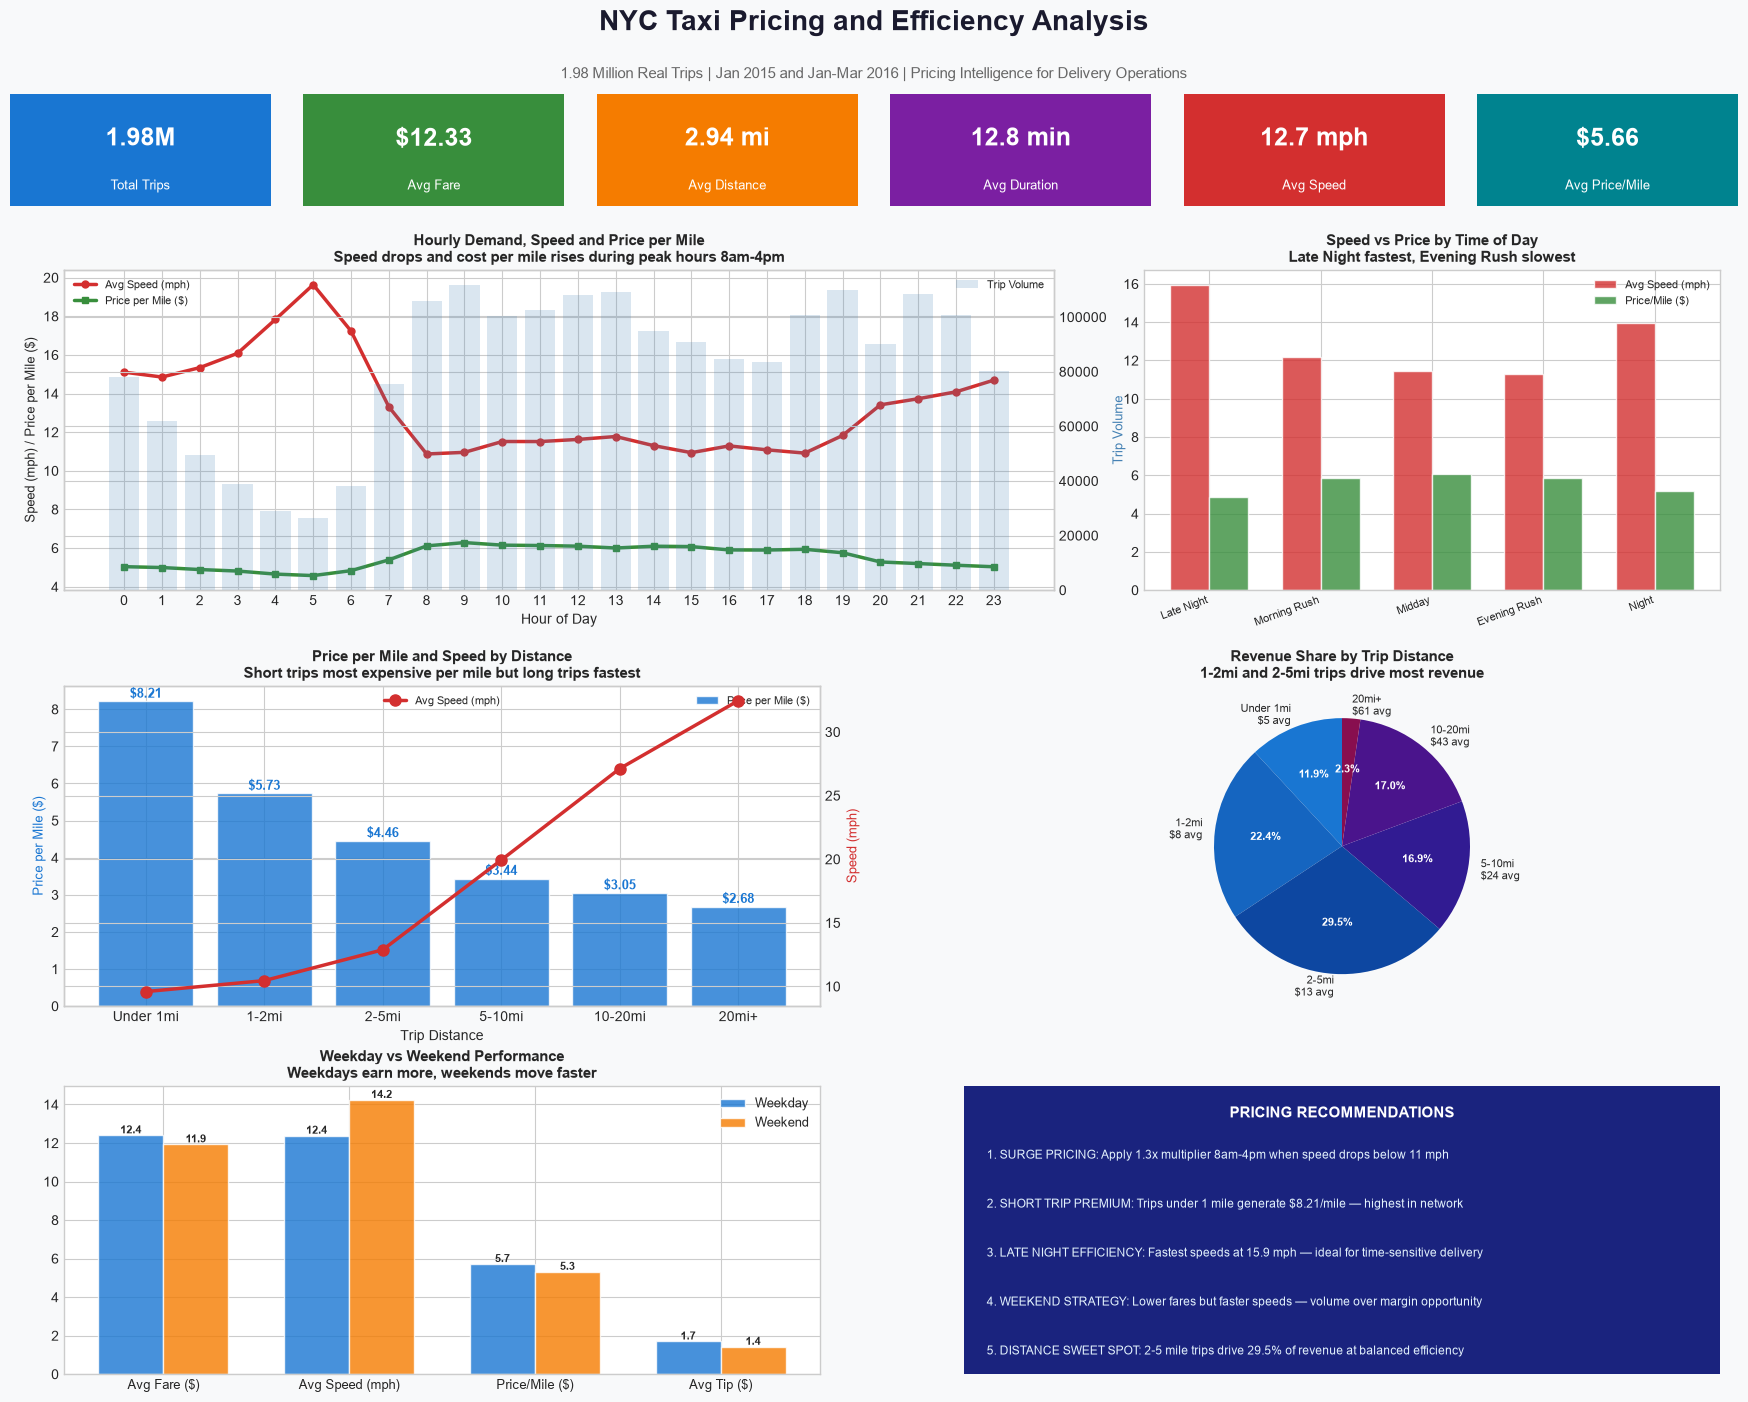

Dashboard saved as pricing_efficiency_dashboard.png


In [10]:
# STEP 4 — PRICING AND EFFICIENCY DASHBOARD
fig = plt.figure(figsize=(18, 16))
fig.patch.set_facecolor('#f8f9fa')

fig.text(0.5, 0.97,
         'NYC Taxi Pricing and Efficiency Analysis',
         ha='center', fontsize=20,
         fontweight='bold', color='#1a1a2e')
fig.text(0.5, 0.94,
         '1.98 Million Real Trips | '
         'Jan 2015 and Jan-Mar 2016 | '
         'Pricing Intelligence for Delivery Operations',
         ha='center', fontsize=11, color='#666666')

# KPI SCORECARDS
kpi_data = [
    ('Total Trips', '1.98M', '#1976d2'),
    ('Avg Fare', '$12.33', '#388e3c'),
    ('Avg Distance', '2.94 mi', '#f57c00'),
    ('Avg Duration', '12.8 min', '#7b1fa2'),
    ('Avg Speed', '12.7 mph', '#d32f2f'),
    ('Avg Price/Mile', '$5.66', '#00838f'),
]

for i, (label, value, color) in enumerate(kpi_data):
    ax_kpi = fig.add_axes(
        [0.02 + i * 0.163, 0.86, 0.145, 0.07])
    ax_kpi.set_facecolor(color)
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_visible(False)
    ax_kpi.text(0.5, 0.60, value,
                ha='center', va='center',
                fontsize=18, fontweight='bold',
                color='white',
                transform=ax_kpi.transAxes)
    ax_kpi.text(0.5, 0.18, label,
                ha='center', va='center',
                fontsize=9, color='white',
                transform=ax_kpi.transAxes)

# CHART 1 — Hourly demand and speed
ax1 = fig.add_axes([0.05, 0.62, 0.55, 0.20])

ax1_twin = ax1.twinx()

ax1_twin.bar(hourly['pickup_hour'],
             hourly['total_trips'],
             color='steelblue', alpha=0.2,
             label='Trip Volume')
ax1_twin.set_ylabel('Trip Volume',
                    color='steelblue', fontsize=9)

ax1.plot(hourly['pickup_hour'],
         hourly['avg_speed'],
         color='#d32f2f', linewidth=2.5,
         marker='o', markersize=5,
         label='Avg Speed (mph)')

ax1.plot(hourly['pickup_hour'],
         hourly['avg_price_per_mile'],
         color='#388e3c', linewidth=2.5,
         marker='s', markersize=5,
         label='Price per Mile ($)')

ax1.set_xlabel('Hour of Day', fontsize=10)
ax1.set_ylabel('Speed (mph) / Price per Mile ($)',
               fontsize=9)
ax1.set_title(
    'Hourly Demand, Speed and Price per Mile\n'
    'Speed drops and cost per mile rises '
    'during peak hours 8am-4pm',
    fontweight='bold', fontsize=11)
ax1.set_xticks(range(0, 24))
ax1.legend(loc='upper left', fontsize=8)
ax1_twin.legend(loc='upper right', fontsize=8)
ax1.set_facecolor('#ffffff')

# CHART 2 — Time of day efficiency
ax2 = fig.add_axes([0.65, 0.62, 0.32, 0.20])

time_order_plot = [
    'Late Night', 'Morning Rush',
    'Midday', 'Evening Rush', 'Night'
]
time_plot = time_pricing.set_index(
    'time_of_day').loc[time_order_plot]

x = np.arange(len(time_order_plot))
width = 0.35

bars_speed = ax2.bar(x - width/2,
                     time_plot['avg_speed'],
                     width, label='Avg Speed (mph)',
                     color='#d32f2f', alpha=0.8,
                     edgecolor='white')

bars_price = ax2.bar(x + width/2,
                     time_plot['avg_price_per_mile'],
                     width, label='Price/Mile ($)',
                     color='#388e3c', alpha=0.8,
                     edgecolor='white')

ax2.set_xticks(x)
ax2.set_xticklabels(time_order_plot,
                    rotation=20, ha='right',
                    fontsize=8)
ax2.set_title(
    'Speed vs Price by Time of Day\n'
    'Late Night fastest, Evening Rush slowest',
    fontweight='bold', fontsize=11)
ax2.legend(fontsize=8)
ax2.set_facecolor('#ffffff')

# CHART 3 — Distance bucket analysis
ax3 = fig.add_axes([0.05, 0.36, 0.42, 0.20])

distance_plot = distance_pricing.copy()

ax3_twin = ax3.twinx()

bars = ax3.bar(
    distance_plot['distance_bucket'].astype(str),
    distance_plot['avg_price_per_mile'],
    color='#1976d2', alpha=0.8,
    edgecolor='white', label='Price per Mile ($)')

ax3_twin.plot(
    distance_plot['distance_bucket'].astype(str),
    distance_plot['avg_speed'],
    color='#d32f2f', linewidth=2.5,
    marker='o', markersize=8,
    label='Avg Speed (mph)')

for bar, val in zip(
    bars, distance_plot['avg_price_per_mile']):
    ax3.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.1,
        f'${val:.2f}',
        ha='center', fontsize=9,
        fontweight='bold', color='#1976d2')

ax3.set_xlabel('Trip Distance', fontsize=10)
ax3.set_ylabel('Price per Mile ($)',
               color='#1976d2', fontsize=9)
ax3_twin.set_ylabel('Speed (mph)',
                    color='#d32f2f', fontsize=9)
ax3.set_title(
    'Price per Mile and Speed by Distance\n'
    'Short trips most expensive per mile '
    'but long trips fastest',
    fontweight='bold', fontsize=11)
ax3.legend(loc='upper right', fontsize=8)
ax3_twin.legend(loc='upper center', fontsize=8)
ax3.set_facecolor('#ffffff')

# CHART 4 — Revenue share by distance
ax4 = fig.add_axes([0.55, 0.36, 0.42, 0.20])

colors_dist = [
    '#1976d2', '#1565c0', '#0d47a1',
    '#311b92', '#4a148c', '#880e4f'
]

wedges, texts, autotexts = ax4.pie(
    distance_plot['revenue_share'],
    labels=[
        f"{row['distance_bucket']}\n"
        f"${row['avg_fare']:.0f} avg"
        for _, row in distance_plot.iterrows()
    ],
    colors=colors_dist,
    autopct='%1.1f%%',
    startangle=90,
    textprops={'fontsize': 8})

for autotext in autotexts:
    autotext.set_color('white')
    autotext.set_fontweight('bold')
    autotext.set_fontsize(8)

ax4.set_title(
    'Revenue Share by Trip Distance\n'
    '1-2mi and 2-5mi trips drive most revenue',
    fontweight='bold', fontsize=11)

# CHART 5 — Weekday vs Weekend
ax5 = fig.add_axes([0.05, 0.13, 0.42, 0.18])

metrics = ['avg_fare', 'avg_speed',
           'avg_price_per_mile', 'avg_tip']
metric_labels = ['Avg Fare ($)', 'Avg Speed (mph)',
                 'Price/Mile ($)', 'Avg Tip ($)']

weekday_vals = week_pricing[
    week_pricing['day_type'] == 'Weekday'
][metrics].values[0]

weekend_vals = week_pricing[
    week_pricing['day_type'] == 'Weekend'
][metrics].values[0]

x = np.arange(len(metrics))
width = 0.35

bars_wd = ax5.bar(x - width/2, weekday_vals,
                  width, label='Weekday',
                  color='#1976d2', edgecolor='white',
                  alpha=0.8)
bars_we = ax5.bar(x + width/2, weekend_vals,
                  width, label='Weekend',
                  color='#f57c00', edgecolor='white',
                  alpha=0.8)

ax5.set_xticks(x)
ax5.set_xticklabels(metric_labels, fontsize=9)
ax5.set_title(
    'Weekday vs Weekend Performance\n'
    'Weekdays earn more, weekends move faster',
    fontweight='bold', fontsize=11)
ax5.legend(fontsize=9)
ax5.set_facecolor('#ffffff')

for bar, val in zip(bars_wd, weekday_vals):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.1,
             f'{val:.1f}', ha='center',
             fontsize=8, fontweight='bold')

for bar, val in zip(bars_we, weekend_vals):
    ax5.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.1,
             f'{val:.1f}', ha='center',
             fontsize=8, fontweight='bold')

# RECOMMENDATIONS BOX
ax_rec = fig.add_axes([0.55, 0.13, 0.42, 0.18])
ax_rec.set_facecolor('#1a237e')
ax_rec.set_xticks([])
ax_rec.set_yticks([])
for spine in ax_rec.spines.values():
    spine.set_visible(False)

recs = [
    "1. SURGE PRICING: Apply 1.3x multiplier "
    "8am-4pm when speed drops below 11 mph",
    "2. SHORT TRIP PREMIUM: Trips under 1 mile "
    "generate $8.21/mile — highest in network",
    "3. LATE NIGHT EFFICIENCY: Fastest speeds "
    "at 15.9 mph — ideal for time-sensitive delivery",
    "4. WEEKEND STRATEGY: Lower fares but faster "
    "speeds — volume over margin opportunity",
    "5. DISTANCE SWEET SPOT: 2-5 mile trips drive "
    "29.5% of revenue at balanced efficiency"
]

ax_rec.text(0.5, 0.93,
            'PRICING RECOMMENDATIONS',
            ha='center', va='top',
            fontsize=11, fontweight='bold',
            color='white',
            transform=ax_rec.transAxes)

for i, rec in enumerate(recs):
    ax_rec.text(0.03, 0.78 - i * 0.17, rec,
                ha='left', va='top',
                fontsize=8.5, color='#e3f2fd',
                transform=ax_rec.transAxes)

plt.savefig('pricing_efficiency_dashboard.png',
            dpi=150, bbox_inches='tight',
            facecolor='#f8f9fa')
plt.show()
print("Dashboard saved as pricing_efficiency_dashboard.png")

In [11]:
print("""
================================================================
NYC TAXI PRICING AND EFFICIENCY ANALYSIS — EXECUTIVE SUMMARY
1.98 Million Real Trips | Jan 2015 and Jan-Mar 2016
================================================================

DATASET
  Total trips analysed:    1,979,249
  Average fare:            $12.33
  Average distance:        2.94 miles
  Average duration:        12.8 minutes
  Average speed:           12.7 mph
  Average price per mile:  $5.66

================================================================
FINDING 1 — PEAK HOURS KILL EFFICIENCY
================================================================
  Evening Rush speed:      11.3 mph (slowest)
  Late Night speed:        15.9 mph (fastest)
  Speed difference:        41% faster at night
  
  Cost per mile at peak:   $6.09 (8am-9am)
  Cost per mile at night:  $4.89 (Late Night)
  
  Key Insight: When demand is highest speed drops
  and cost per mile rises. Surge pricing during
  8am to 4pm compensates for lower delivery
  efficiency in congested conditions.

================================================================
FINDING 2 — SHORT TRIPS ARE MOST PROFITABLE PER MILE
================================================================
  Under 1 mile trips:      $8.21 per mile
  1 to 2 mile trips:       $5.73 per mile
  2 to 5 mile trips:       $4.46 per mile
  5 to 10 mile trips:      $3.44 per mile
  10 to 20 mile trips:     $3.05 per mile
  
  Key Insight: Price per mile drops 63% from
  short to long trips. But long trips generate
  higher absolute revenue ($61 vs $5 avg fare)
  and move at 32.5 mph vs 9.6 mph for short trips.
  Short trips are revenue efficient per mile.
  Long trips are time efficient.

================================================================
FINDING 3 — REVENUE CONCENTRATION IN MID-RANGE TRIPS
================================================================
  2 to 5 mile trips:       29.5% of all revenue
  1 to 2 mile trips:       22.4% of all revenue
  10 to 20 mile trips:     17.0% of all revenue
  5 to 10 mile trips:      16.9% of all revenue
  
  Key Insight: The 1 to 5 mile range drives 52%
  of total revenue. This is the sweet spot for
  any urban delivery pricing model.

================================================================
FINDING 4 — WEEKDAY VS WEEKEND TRADE-OFF
================================================================
  Weekday avg fare:        $12.40
  Weekend avg fare:        $11.93
  Weekday avg speed:       12.4 mph
  Weekend avg speed:       14.2 mph
  Weekday avg tip:         $1.70
  Weekend avg tip:         $1.42
  
  Key Insight: Weekends are 15% faster but
  generate 4% less fare and 16% less tip.
  Weekdays are higher value, weekends are
  higher volume opportunity.

================================================================
PRICING RECOMMENDATIONS
================================================================
  1. SURGE PRICING: Apply 1.3x multiplier
     8am to 4pm when speed drops below 11 mph.
     Compensates for lower delivery efficiency
     during peak congestion.

  2. SHORT TRIP PREMIUM: Trips under 1 mile
     generate $8.21 per mile. Maintain minimum
     fare floor to protect margin on short trips.

  3. LATE NIGHT EFFICIENCY: Fastest speeds at
     15.9 mph make late night ideal for
     time-sensitive or premium deliveries.

  4. WEEKEND VOLUME STRATEGY: Lower fares but
     faster speeds. Price for volume on weekends
     rather than margin optimisation.

  5. DISTANCE SWEET SPOT: Build pricing model
     around the 2 to 5 mile range which drives
     29.5% of revenue at balanced speed and cost.

================================================================
TOOLS USED
  Python, Pandas, NumPy, Matplotlib,
  Seaborn, Jupyter Notebook

DATASET
  NYC Yellow Taxi Trip Data 2015-2016
  Available at: kaggle.com/datasets/elemento/
  nyc-yellow-taxi-trip-data
================================================================
""")


NYC TAXI PRICING AND EFFICIENCY ANALYSIS — EXECUTIVE SUMMARY
1.98 Million Real Trips | Jan 2015 and Jan-Mar 2016

DATASET
  Total trips analysed:    1,979,249
  Average fare:            $12.33
  Average distance:        2.94 miles
  Average duration:        12.8 minutes
  Average speed:           12.7 mph
  Average price per mile:  $5.66

FINDING 1 — PEAK HOURS KILL EFFICIENCY
  Evening Rush speed:      11.3 mph (slowest)
  Late Night speed:        15.9 mph (fastest)
  Speed difference:        41% faster at night

  Cost per mile at peak:   $6.09 (8am-9am)
  Cost per mile at night:  $4.89 (Late Night)

  Key Insight: When demand is highest speed drops
  and cost per mile rises. Surge pricing during
  8am to 4pm compensates for lower delivery
  efficiency in congested conditions.

FINDING 2 — SHORT TRIPS ARE MOST PROFITABLE PER MILE
  Under 1 mile trips:      $8.21 per mile
  1 to 2 mile trips:       $5.73 per mile
  2 to 5 mile trips:       $4.46 per mile
  5 to 10 mile trips:      $3